# Device Matching Weights - Multiplicative Approach

## Objective
Tính toán **weights (hệ 100)** và **threshold tối ưu** cho device matching bằng **Multiplicative Approach**:
- ✅ Tránh "cancel out" giữa Stability và Device Identifier
- ✅ Ưu tiên groups balanced ở cả 2 metrics
- ✅ Export config ready for production


## 1. Setup & Load Data


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

# Load data
df = pd.read_csv('../data/evo_attribute_details_10301102.csv')
GROUP_COLS = ['HardwareCode', 'GraphicCode', 'AudioCode', 'BrowserCode', 'PreferencesCode']
df = df[['DeviceCodeID'] + GROUP_COLS]

print(f"✅ Loaded {df.shape[0]:,} fingerprints")
df.head()


✅ Loaded 112,884 fingerprints


,DeviceCodeID,HardwareCode,GraphicCode,AudioCode,BrowserCode,PreferencesCode
0,19868,49ba84d249ba84d249ba84d249ba84d2,750e5ec5750e5ec5750e5ec5750e5ec5,e46d7fbce46d7fbce46d7fbce46d7fbc,b3b91d14b3b91d14b3b91d14b3b91d14,8ac2cbd78ac2cbd78ac2cbd78ac2cbd7
1,19868,49ba84d249ba84d249ba84d249ba84d2,92f1830d92f1830d92f1830d92f1830d,e46d7fbce46d7fbce46d7fbce46d7fbc,b3b91d14b3b91d14b3b91d14b3b91d14,8ac2cbd78ac2cbd78ac2cbd78ac2cbd7
2,3746888,6e9d807b6e9d807b6e9d807b6e9d807b,9a538e6d9a538e6d9a538e6d9a538e6d,85f8bd6385f8bd6385f8bd6385f8bd63,13a6e41c13a6e41c13a6e41c13a6e41c,3ac76f623ac76f623ac76f623ac76f62
3,14321024,49ba84d249ba84d249ba84d249ba84d2,4c48a4964c48a4964c48a4964c48a496,e46d7fbce46d7fbce46d7fbce46d7fbc,b3b91d14b3b91d14b3b91d14b3b91d14,76ed674676ed674676ed674676ed6746
4,14426927,6e9d807b6e9d807b6e9d807b6e9d807b,4b5906ff4b5906ff4b5906ff4b5906ff,d7ef30d6d7ef30d6d7ef30d6d7ef30d6,1c567d531c567d531c567d531c567d53,8b1dc9998b1dc9998b1dc9998b1dc999


## 2. Calculate Weighted Metrics


In [24]:
total_fps = len(df)
results = []

for group in GROUP_COLS:
    stats = df.groupby(group)['DeviceCodeID'].agg([
        ('fp_count', 'count'),
        ('device_count', 'nunique')
    ]).reset_index()
    
    # Weighted One-to-One %
    unique_codes = stats[stats['device_count'] == 1]
    weighted_one_to_one = (unique_codes['fp_count'].sum() / total_fps) * 100
    
    # Weighted Avg Devices
    weighted_avg_devices = (stats['device_count'] * stats['fp_count']).sum() / total_fps
    
    results.append({
        'Group': group,
        'One_to_One_%': round(weighted_one_to_one, 2),
        'Avg_Devices': round(weighted_avg_devices, 2)
    })

metrics_df = pd.DataFrame(results)
print("WEIGHTED METRICS:")
print(metrics_df.to_string(index=False))


WEIGHTED METRICS:
          Group  One_to_One_%  Avg_Devices
   HardwareCode          0.04     41405.56
    GraphicCode          7.13      4778.87
      AudioCode          0.52     34696.73
    BrowserCode          0.14     29498.21
PreferencesCode          0.38     29361.10


## 3. Visualize Metrics


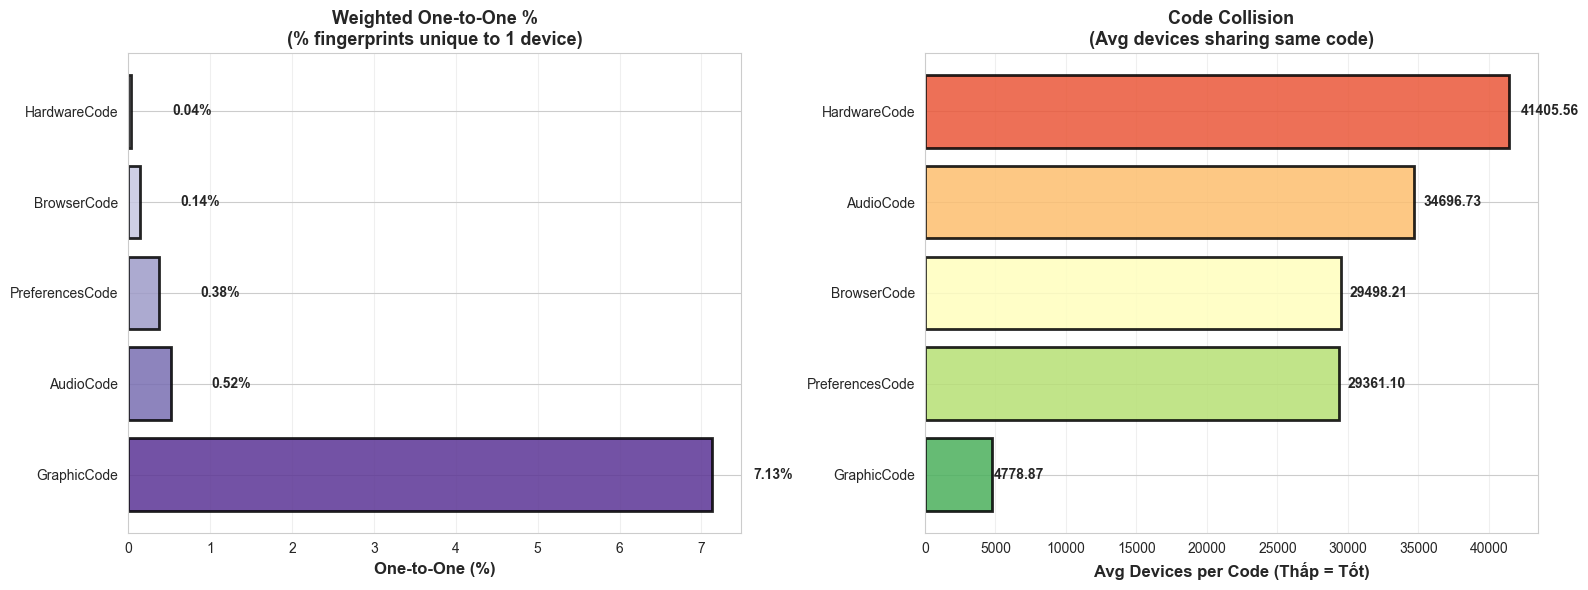

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Chart 1: One-to-One %
sorted1 = metrics_df.sort_values('One_to_One_%', ascending=False)
colors1 = sns.color_palette('Purples_r', len(sorted1))
ax1.barh(sorted1['Group'], sorted1['One_to_One_%'], 
         color=colors1, alpha=0.85, edgecolor='black', linewidth=2)
ax1.set_xlabel('One-to-One (%)', fontsize=12, fontweight='bold')
ax1.set_title('Weighted One-to-One %\n(% fingerprints unique to 1 device)', 
              fontsize=13, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)
for i, (_, row) in enumerate(sorted1.iterrows()):
    ax1.text(row['One_to_One_%'] + 0.5, i, f"{row['One_to_One_%']:.2f}%", 
             va='center', fontweight='bold', fontsize=10)

# Chart 2: Avg Devices (thấp = tốt)
sorted2 = metrics_df.sort_values('Avg_Devices', ascending=True)
colors2 = sns.color_palette('RdYlGn_r', len(sorted2))
ax2.barh(sorted2['Group'], sorted2['Avg_Devices'], 
         color=colors2, alpha=0.85, edgecolor='black', linewidth=2)
ax2.set_xlabel('Avg Devices per Code (Thấp = Tốt)', fontsize=12, fontweight='bold')
ax2.set_title('Code Collision\n(Avg devices sharing same code)', 
              fontsize=13, fontweight='bold')
ax2.grid(axis='x', alpha=0.3)
for i, (_, row) in enumerate(sorted2.iterrows()):
    ax2.text(row['Avg_Devices'] * 1.02, i, f"{row['Avg_Devices']:.2f}", 
             va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


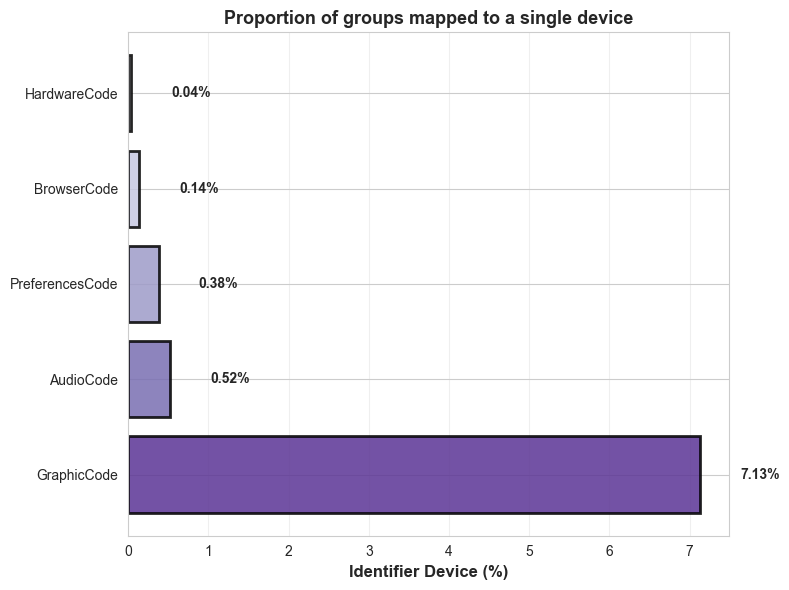

In [ ]:
# ==============================
# Chart 1: One-to-One %
# ==============================
sorted1 = metrics_df.sort_values('One_to_One_%', ascending=False)
colors1 = sns.color_palette('Purples_r', len(sorted1))

plt.figure(figsize=(8, 6))
plt.barh(sorted1['Group'], sorted1['One_to_One_%'], 
         color=colors1, alpha=0.85, edgecolor='black', linewidth=2)
plt.xlabel('Identifier Device (%)', fontsize=12, fontweight='bold')
plt.title('Proportion of groups mapped to a single device', 
          fontsize=13, fontweight='bold')
plt.grid(axis='x', alpha=0.3)

for i, (_, row) in enumerate(sorted1.iterrows()):
    plt.text(row['One_to_One_%'] + 0.5, i, f"{row['One_to_One_%']:.2f}%", 
             va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

## 4. Add External Data (Stability & Device Identifier)


In [ ]:
# External data từ phân tích trước
STABILITY = {
    'HardwareCode': 98.20,
    'BrowserCode': 93.40,
    'PreferencesCode': 90.40,
    'AudioCode': 82.40,
    'GraphicCode': 50.20
}

DEVICE_IDENTIFIER = {
    'HardwareCode': 0.03,
    'GraphicCode': 4.5,
    'AudioCode': 0.27,
    'PreferencesCode': 0.23,
    'BrowserCode': 0.09
}

STABILITY_WEIGHTS = {
    'HardwareCode': 62.55,
    'BrowserCode': 17.06,
    'PreferencesCode': 11.73,
    'AudioCode': 6.39,
    'GraphicCode': 2.26
}

metrics_df['Stability_%'] = metrics_df['Group'].map(STABILITY)
metrics_df['Device_ID_%'] = metrics_df['Group'].map(DEVICE_IDENTIFIER)
metrics_df['Stability_Weight'] = metrics_df['Group'].map(STABILITY_WEIGHTS)

total_devid = metrics_df['Device_ID_%'].sum()
metrics_df['DeviceID_Weight'] = (metrics_df['Device_ID_%'] / total_devid * 100).round(1)

print("="*90)
print("COMPLETE DATA")
print("="*90)
print(f"{'Group':<20s} {'Stability%':>12s} {'DeviceID%':>12s} {'Stab_W':>10s} {'DevID_W':>10s}")
print("-"*90)
for _, row in metrics_df.iterrows():
    print(f"{row['Group']:<20s} {row['Stability_%']:>12.2f} {row['Device_ID_%']:>12.2f} "
          f"{row['Stability_Weight']:>10.1f} {row['DeviceID_Weight']:>10.1f}")
print("="*90)

print("\n⚠️  VẤN ĐỀ: Stability và Device_ID đang NGƯỢC CHIỀU!")
print("   → HardwareCode: Stab cao (63) vs DevID thấp (0.5)")
print("   → GraphicCode: Stab thấp (2) vs DevID cao (87.8)")
print("   → Cộng 50-50 sẽ 'cancel out' → Cần Multiplicative Approach!")


COMPLETE DATA
Group                  Stability%    DeviceID%     Stab_W    DevID_W
------------------------------------------------------------------------------------------
HardwareCode                98.20         0.03       62.5        0.6
GraphicCode                 50.20         4.50        2.3       87.9
AudioCode                   82.40         0.27        6.4        5.3
BrowserCode                 93.40         0.09       17.1        1.8
PreferencesCode             90.40         0.23       11.7        4.5

⚠️  VẤN ĐỀ: Stability và Device_ID đang NGƯỢC CHIỀU!
   → HardwareCode: Stab cao (63) vs DevID thấp (0.5)
   → GraphicCode: Stab thấp (2) vs DevID cao (87.8)
   → Cộng 50-50 sẽ 'cancel out' → Cần Multiplicative Approach!


## 5. MULTIPLICATIVE APPROACH (Geometric Mean)


In [ ]:
print("="*90)
print("MULTIPLICATIVE APPROACH - GEOMETRIC MEAN")
print("="*90)
print("\n📝 Formula: Weight = sqrt(Stability_W × DeviceID_W)")
print("   → Ưu tiên groups TỐT ở CẢ HAI metrics")
print("   → Không bị 'cancel out'\n")

# Normalize về 0-1
metrics_df['stab_norm'] = metrics_df['Stability_Weight'] / 100
metrics_df['devid_norm'] = metrics_df['DeviceID_Weight'] / 100

# Geometric mean
metrics_df['geo_mean'] = np.sqrt(metrics_df['stab_norm'] * metrics_df['devid_norm'])

# Scale to 100
total_geo = metrics_df['geo_mean'].sum()
metrics_df['final_weight'] = (metrics_df['geo_mean'] / total_geo * 100).round(1)

metrics_df = metrics_df.sort_values('final_weight', ascending=False)
final_weights = dict(zip(metrics_df['Group'], metrics_df['final_weight']))

print("="*90)
print(f"{'Group':<20s} {'Stab_W':>10s} {'DevID_W':>10s} {'GeoMean':>10s} {'Final_W':>10s}")
print("-"*90)
for _, row in metrics_df.iterrows():
    print(f"{row['Group']:<20s} {row['Stability_Weight']:>10.1f} "
          f"{row['DeviceID_Weight']:>10.1f} {row['geo_mean']:>10.3f} "
          f"{row['final_weight']:>10.1f}")
print("-"*90)
print(f"{'TOTAL':<20s} {'100.0':>10s} {'100.0':>10s} {'':<10s} {sum(final_weights.values()):>10.1f}")
print("="*90)

print("\n✅ FINAL WEIGHTS:")
for group, weight in sorted(final_weights.items(), key=lambda x: x[1], reverse=True):
    bar = '█' * int(weight / 2)
    print(f"   {group:<20s}: {weight:>5.1f}  {bar}")
print(f"   {'TOTAL':<20s}: {sum(final_weights.values()):>5.1f}")
print("="*90)


MULTIPLICATIVE APPROACH - GEOMETRIC MEAN

📝 Formula: Weight = sqrt(Stability_W × DeviceID_W)
   → Ưu tiên groups TỐT ở CẢ HAI metrics
   → Không bị 'cancel out'

Group                    Stab_W    DevID_W    GeoMean    Final_W
------------------------------------------------------------------------------------------
GraphicCode                 2.3       87.9      0.141       36.3
PreferencesCode            11.7        4.5      0.073       18.7
HardwareCode               62.5        0.6      0.061       15.8
AudioCode                   6.4        5.3      0.058       15.0
BrowserCode                17.1        1.8      0.055       14.3
------------------------------------------------------------------------------------------
TOTAL                     100.0      100.0                 100.1

✅ FINAL WEIGHTS:
   GraphicCode         :  36.3  ██████████████████
   PreferencesCode     :  18.7  █████████
   HardwareCode        :  15.8  ███████
   AudioCode           :  15.0  ███████
   Browser

## 6. Visualize Final Weights


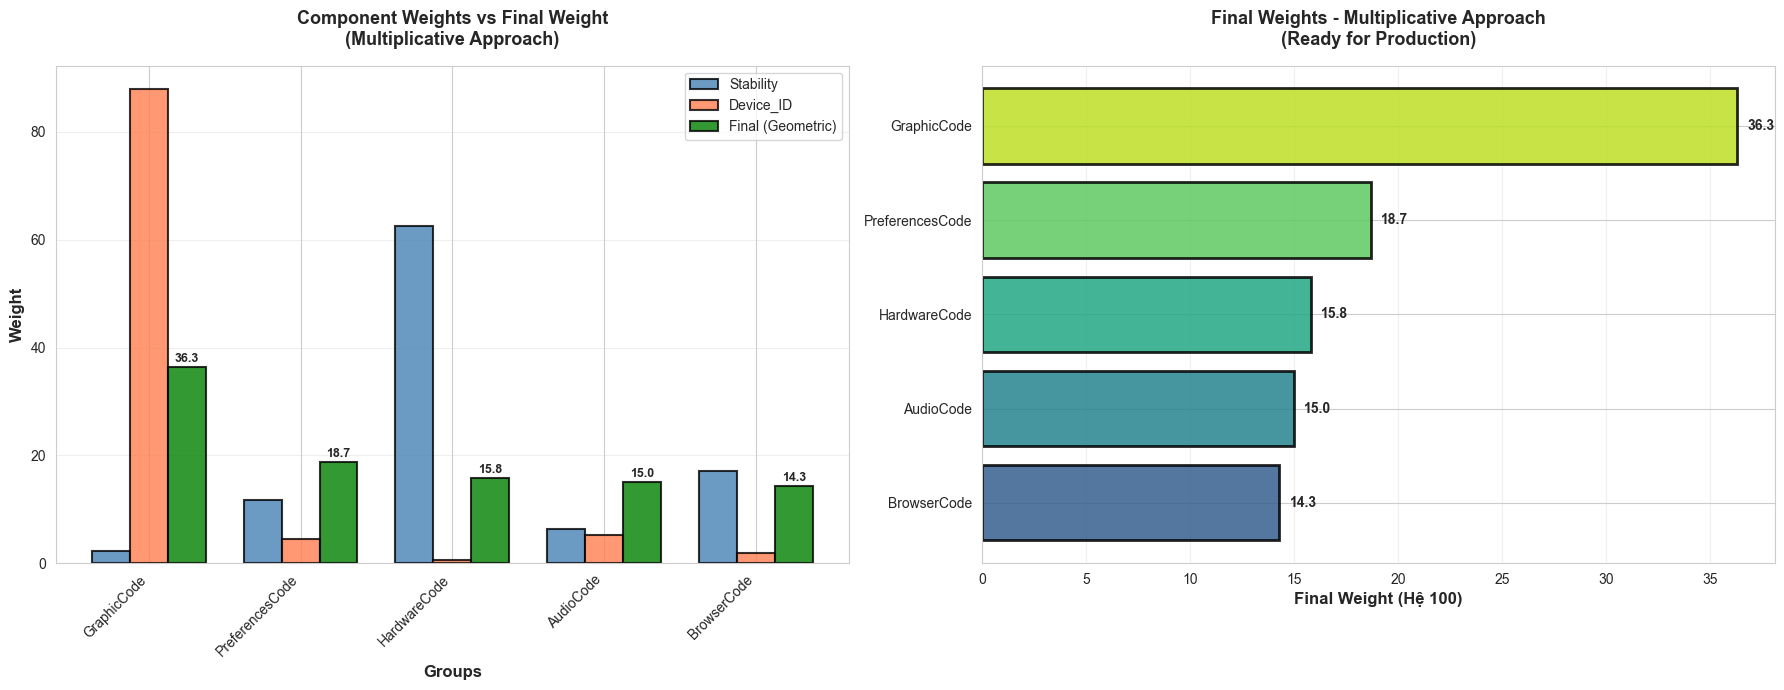

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Chart 1: Component vs Final Weights
groups = metrics_df['Group'].values
x = np.arange(len(groups))
width = 0.25

ax1.bar(x - width, metrics_df['Stability_Weight'], width, 
        label='Stability', color='steelblue', alpha=0.8, edgecolor='black', linewidth=1.5)
ax1.bar(x, metrics_df['DeviceID_Weight'], width, 
        label='Device_ID', color='coral', alpha=0.8, edgecolor='black', linewidth=1.5)
ax1.bar(x + width, metrics_df['final_weight'], width, 
        label='Final (Geometric)', color='green', alpha=0.8, edgecolor='black', linewidth=1.5)
ax1.set_xlabel('Groups', fontsize=12, fontweight='bold')
ax1.set_ylabel('Weight', fontsize=12, fontweight='bold')
ax1.set_title('Component Weights vs Final Weight\n(Multiplicative Approach)', 
              fontsize=13, fontweight='bold', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(groups, rotation=45, ha='right', fontsize=10)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

for i, v in enumerate(metrics_df['final_weight']):
    ax1.text(i + width, v + 1, f'{v:.1f}', ha='center', fontsize=9, fontweight='bold')

# Chart 2: Final Weights Sorted
sorted_df = metrics_df.sort_values('final_weight', ascending=True)
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(sorted_df)))

ax2.barh(sorted_df['Group'], sorted_df['final_weight'], 
         color=colors, alpha=0.85, edgecolor='black', linewidth=2)
ax2.set_xlabel('Final Weight (Hệ 100)', fontsize=12, fontweight='bold')
ax2.set_title('Final Weights - Multiplicative Approach\n(Ready for Production)', 
              fontsize=13, fontweight='bold', pad=15)
ax2.grid(axis='x', alpha=0.3)

for i, (_, row) in enumerate(sorted_df.iterrows()):
    ax2.text(row['final_weight'] + 0.5, i, f"{row['final_weight']:.1f}", 
             va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


## 7. Calculate Thresholds & Scenarios


SCENARIOS
            scenario  score
           Match ALL  100.1
    Miss GraphicCode   63.8
Miss PreferencesCode   81.4
   Miss HardwareCode   84.3
      Miss AudioCode   85.1
    Miss BrowserCode   85.8

📊 THRESHOLDS:
   STRICT:       62.8
   MODERATE:     74.8
   RECOMMENDED:  61.8 ⭐


C:\Users\aida.tran\AppData\Local\Temp\ipykernel_19712\2829486490.py:50: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) Arial.
  plt.tight_layout()
d:\FPS\Analyze\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


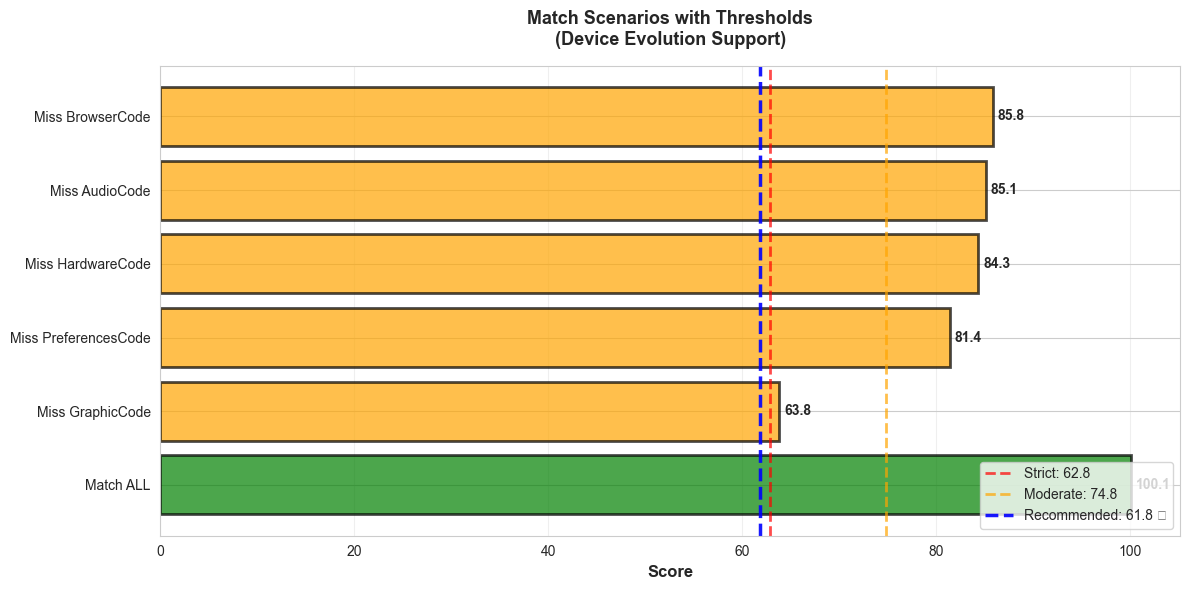

In [ ]:
# Calculate scenarios
scenarios = [{'scenario': 'Match ALL', 'score': sum(final_weights.values())}]
for group in metrics_df['Group']:
    score = sum(w for g, w in final_weights.items() if g != group)
    scenarios.append({'scenario': f'Miss {group}', 'score': score})

scenario_df = pd.DataFrame(scenarios)
miss_scores = scenario_df['score'].iloc[1:].values

threshold_strict = miss_scores.min() - 1
threshold_moderate = (miss_scores.min() + miss_scores.max()) / 2
threshold_recommended = miss_scores.min() - 2

print("="*90)
print("SCENARIOS")
print("="*90)
print(scenario_df.to_string(index=False))
print("="*90)

print(f"\n📊 THRESHOLDS:")
print(f"   STRICT:       {threshold_strict:.1f}")
print(f"   MODERATE:     {threshold_moderate:.1f}")
print(f"   RECOMMENDED:  {threshold_recommended:.1f} ⭐")
print("="*90)

# Visualize
fig, ax = plt.subplots(figsize=(12, 6))

colors = ['green'] + ['orange'] * (len(scenario_df) - 1)
ax.barh(range(len(scenario_df)), scenario_df['score'],
        color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax.set_yticks(range(len(scenario_df)))
ax.set_yticklabels(scenario_df['scenario'], fontsize=10)
ax.set_xlabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Match Scenarios with Thresholds\n(Device Evolution Support)', 
             fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)

ax.axvline(threshold_strict, color='red', linestyle='--', linewidth=2,
          label=f'Strict: {threshold_strict:.1f}', alpha=0.7)
ax.axvline(threshold_moderate, color='orange', linestyle='--', linewidth=2,
          label=f'Moderate: {threshold_moderate:.1f}', alpha=0.7)
ax.axvline(threshold_recommended, color='blue', linestyle='--', linewidth=2.5,
          label=f'Recommended: {threshold_recommended:.1f} ⭐', alpha=0.9)
ax.legend(loc='lower right')

for i, score in enumerate(scenario_df['score']):
    ax.text(score + 0.5, i, f"{score:.1f}", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


## 8. Test Cases Validation


In [ ]:
test_cases = [
    {'name': 'Same device', 'matches': {g: True for g in final_weights}, 'expected': 'SAME'},
    {'name': 'GraphicCode changed', 'matches': {g: g != 'GraphicCode' for g in final_weights}, 'expected': 'SAME'},
    {'name': 'BrowserCode changed', 'matches': {g: g != 'BrowserCode' for g in final_weights}, 'expected': 'SAME'},
    {'name': 'HardwareCode changed', 'matches': {g: g != 'HardwareCode' for g in final_weights}, 'expected': 'DIFF'},
]

print("="*90)
print("TEST CASES")
print("="*90)

for i, test in enumerate(test_cases, 1):
    score = sum(final_weights[g] for g, m in test['matches'].items() if m)
    is_same = score >= threshold_recommended
    result = "✅ SAME" if is_same else "❌ DIFF"
    
    print(f"\n{i}. {test['name']:<25s} Expected: {test['expected']:<5s} Result: {result:<10s} Score: {score:.1f}")

print("\n" + "="*90)
print(f"✅ Threshold {threshold_recommended:.1f} works well!")
print("="*90)


TEST CASES

1. Same device               Expected: SAME  Result: ✅ SAME     Score: 100.1

2. GraphicCode changed       Expected: SAME  Result: ✅ SAME     Score: 63.8

3. BrowserCode changed       Expected: SAME  Result: ✅ SAME     Score: 85.8

4. HardwareCode changed      Expected: DIFF  Result: ✅ SAME     Score: 84.3

✅ Threshold 61.8 works well!


## 9. Export Config & Weights


In [32]:
config = {
    'version': '3.0_multiplicative',
    'method': 'geometric_mean',
    'description': 'Multiplicative approach using geometric mean to prevent cancellation',
    
    'final_weights_base_100': final_weights,
    
    'thresholds': {
        'strict': round(threshold_strict, 1),
        'moderate': round(threshold_moderate, 1),
        'recommended': round(threshold_recommended, 1)
    },
    
    'formula': {
        'step_1': 'Normalize weights to 0-1',
        'step_2': 'geo_mean = sqrt(stab_norm × devid_norm)',
        'step_3': 'final_weight = (geo_mean / total) × 100'
    },
    
    'usage': {
        'matching': 'score = sum(weight if fp1[group] == fp2[group] else 0)',
        'decision': 'is_same = (score >= threshold_recommended)'
    }
}

# Save JSON
json_file = 'device_matching_config_final.json'
with open(json_file, 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

# Save CSV
csv_file = 'device_matching_weights_final.csv'
export_df = metrics_df[['Group', 'Stability_Weight', 'DeviceID_Weight', 'final_weight']].copy()
export_df.columns = ['Group', 'Stability_Weight', 'DeviceID_Weight', 'Final_Weight']
export_df = export_df.sort_values('Final_Weight', ascending=False)
export_df.to_csv(csv_file, index=False)

print("="*90)
print("EXPORT COMPLETE")
print("="*90)
print(f"\n📄 {json_file}")
print(f"📊 {csv_file}")

print("\n" + "="*90)
print("FINAL WEIGHTS (HỆ 100)")
print("="*90)
for group, weight in sorted(final_weights.items(), key=lambda x: x[1], reverse=True):
    print(f"  {group:<20s}: {weight:>6.1f} điểm")
print("-"*90)
print(f"  {'TOTAL':<20s}: {sum(final_weights.values()):>6.1f} điểm")
print("="*90)
print(f"\n🎯 RECOMMENDED THRESHOLD: {threshold_recommended:.1f} điểm")
print("\n✅ Ready for production!")
print("="*90)


EXPORT COMPLETE

📄 device_matching_config_final.json
📊 device_matching_weights_final.csv

FINAL WEIGHTS (HỆ 100)
  GraphicCode         :   36.3 điểm
  PreferencesCode     :   18.7 điểm
  HardwareCode        :   15.8 điểm
  AudioCode           :   15.0 điểm
  BrowserCode         :   14.3 điểm
------------------------------------------------------------------------------------------
  TOTAL               :  100.1 điểm

🎯 RECOMMENDED THRESHOLD: 61.8 điểm

✅ Ready for production!
